In [ ]:

import pandas as pd
import numpy as np

print("AI-Based Text Classification System")
print("Spam Message Detection Project")
print("Libraries imported successfully!")


AI-Based Text Classification System
Spam Message Detection Project
Libraries imported successfully!


In [ ]:

import pandas as pd
import zipfile
import io
import urllib.request

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

response = urllib.request.urlopen(url)
zip_data = zipfile.ZipFile(io.BytesIO(response.read()))

with zip_data.open("SMSSpamCollection") as file:
    df = pd.read_csv(
        file,
        sep="\t",
        header=None,
        names=["label", "message"],
        encoding="utf-8"
    )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:

print("Dataset Information:")
df.info()

print("\nNumber of messages in each category:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Number of messages in each category:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [ ]:

# Step 6: Data cleaning

print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows with missing labels or messages
df = df.dropna(subset=["label", "message"]).copy()

# Keep only the expected categories
df = df[df["label"].isin(["ham", "spam"])].copy()

print("\nDataset after cleaning:")
print("Number of rows:", len(df))
print("Missing values:")
print(df.isnull().sum())

print("\nLabel counts:")
print(df["label"].value_counts())


Missing values before cleaning:
label      0
message    0
dtype: int64

Duplicate rows: 403

Dataset after cleaning:
Number of rows: 5169
Missing values:
label      0
message    0
dtype: int64

Label counts:
label
ham     4516
spam     653
Name: count, dtype: int64


In [ ]:

# Convert text labels into numerical labels

df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["label", "label_num"]].head(10))

print("\nLabel mapping:")
print("Ham (legitimate message) = 0")
print("Spam (unwanted message) = 1")


  label  label_num
0   ham          0
1   ham          0
2  spam          1
3   ham          0
4   ham          0
5  spam          1
6   ham          0
7   ham          0
8  spam          1
9  spam          1

Label mapping:
Ham (legitimate message) = 0
Spam (unwanted message) = 1


In [ ]:

from sklearn.model_selection import train_test_split

# Input: SMS messages
X = df["message"]

# Target: numerical labels (0 = ham, 1 = spam)
y = df["label_num"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining data is ready!")
print("Testing data is ready!")


Training messages: 4135
Testing messages: 1034

Training data is ready!
Testing data is ready!


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

# Learn vocabulary from training messages only
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert test messages using the same learned vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)


TF-IDF conversion completed!
Training data shape: (4135, 7414)
Testing data shape: (1034, 7414)


In [ ]:

from sklearn.naive_bayes import MultinomialNB

# Create the machine learning model
model = MultinomialNB()

# Train the model using the training data
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [ ]:

from sklearn.metrics import accuracy_score

# Predict labels for test messages
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print(f"Accuracy: {accuracy * 100:.2f}%")


Model Evaluation
-------------------------
Accuracy: 96.71%


Classification Report:
                precision    recall  f1-score   support

Ham (Not Spam)       0.96      1.00      0.98       903
          Spam       1.00      0.74      0.85       131

      accuracy                           0.97      1034
     macro avg       0.98      0.87      0.92      1034
  weighted avg       0.97      0.97      0.96      1034



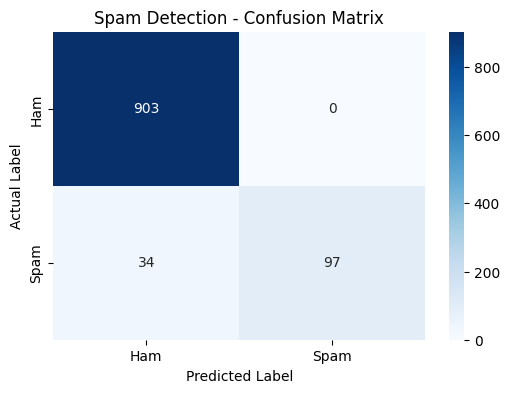

In [ ]:

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Detailed performance report
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham (Not Spam)", "Spam"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Spam Detection - Confusion Matrix")
plt.show()


In [ ]:

def predict_message(message):
    # Convert the input message into TF-IDF features
    message_tfidf = tfidf.transform([message])

    # Predict the message category
    prediction = model.predict(message_tfidf)[0]

    # Display the result
    if prediction == 1:
        print("Result: SPAM")
        print("Warning: This message may be unwanted or suspicious.")
    else:
        print("Result: NOT SPAM")
        print("This message appears to be legitimate.")

# Try an example
predict_message("Congratulations! You won a free prize. Click now!")


Result: SPAM


In [ ]:

predict_message("Hey, are we meeting at college tomorrow?")


Result: NOT SPAM
This message appears to be legitimate.


In [ ]:

predict_message("URGENT! Claim your free cash prize now!")


Result: SPAM


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create and train a second model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Predict on the same test data
lr_pred = lr_model.predict(X_test_tfidf)

# Compare performance
print("Naive Bayes Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, lr_pred) * 100, 2), "%")

print("\nLogistic Regression Report:")
print(classification_report(
    y_test,
    lr_pred,
    target_names=["Ham (Not Spam)", "Spam"]
))


Naive Bayes Accuracy: 96.71 %
Logistic Regression Accuracy: 95.65 %

Logistic Regression Report:
                precision    recall  f1-score   support

Ham (Not Spam)       0.95      1.00      0.98       903
          Spam       0.98      0.67      0.80       131

      accuracy                           0.96      1034
     macro avg       0.97      0.83      0.89      1034
  weighted avg       0.96      0.96      0.95      1034



In [ ]:

import joblib
import os

# Choose the model with better spam detection
# For now, save Logistic Regression
best_model = lr_model

# Save the trained model and text vectorizer
joblib.dump(best_model, "spam_detection_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("Vectorizer saved successfully!")

print("\nFiles created:")
print(os.listdir())


Model saved successfully!
Vectorizer saved successfully!

Files created:
['.config', 'spam_detection_model.pkl', 'tfidf_vectorizer.pkl', 'sample_data']


In [ ]:

from google.colab import files

files.download("spam_detection_model.pkl")
files.download("tfidf_vectorizer.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip -q install gradio


In [1]:

import gradio as gr

def check_message(message):
    if not message or not message.strip():
        return "Please enter a message."

    # Convert message into TF-IDF features
    message_tfidf = tfidf.transform([message])

    # Predict using the trained model
    prediction = best_model.predict(message_tfidf)[0]

    if prediction == 1:
        return "⚠️ SPAM MESSAGE\nBe careful. This message may be unwanted."
    else:
        return "✅ NOT SPAM\nThe model classified this as a legitimate message."

demo = gr.Interface(
    fn=check_message,
    inputs=gr.Textbox(
        lines=4,
        placeholder="Type or paste a message here...",
        label="Enter your SMS message"
    ),
    outputs=gr.Textbox(label="Prediction"),
    title="AI-Based Spam Message Detection",
    description="Enter an SMS message to classify it using machine learning."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d11d9bb25a748bc48d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
